<a href="https://colab.research.google.com/github/BenjaminNaveas/2.8-regresion-lineal/blob/main/Actividad_2_8_Bloques_1_y_2_Benjamin_Naveas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Actividad 2.8: Laboratorio - Implementación de Regresión Lineal
**Estudiante:** Benjamín Eduardo Naveas Molina | **Asignatura:** IEI097 · Minería de Datos
*Cuaderno 1: Bloque 1 (Regresión Simple) y Bloque 2 (Regresión Múltiple)*

In [1]:
# 1. PREPARACIÓN DEL ENTORNO Y SECRETS
!pip install kagglehub scikit-learn statsmodels seaborn --upgrade -q
import kagglehub, os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from google.colab import userdata
import warnings
warnings.filterwarnings('ignore')

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump({"username": userdata.get('KAGGLE_USERNAME'), "key": userdata.get('KAGGLE_KEY')}, f)
os.chmod('/root/.kaggle/kaggle.json', 0o600)

# 🔬 Bloque 1: Regresión lineal simple (Breast Cancer)
**Carga e inspección:** Se descartan las columnas `id` (identificador sin valor numérico predictivo) y `Unnamed: 32` (columna generada por error al final del CSV con valores nulos).

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


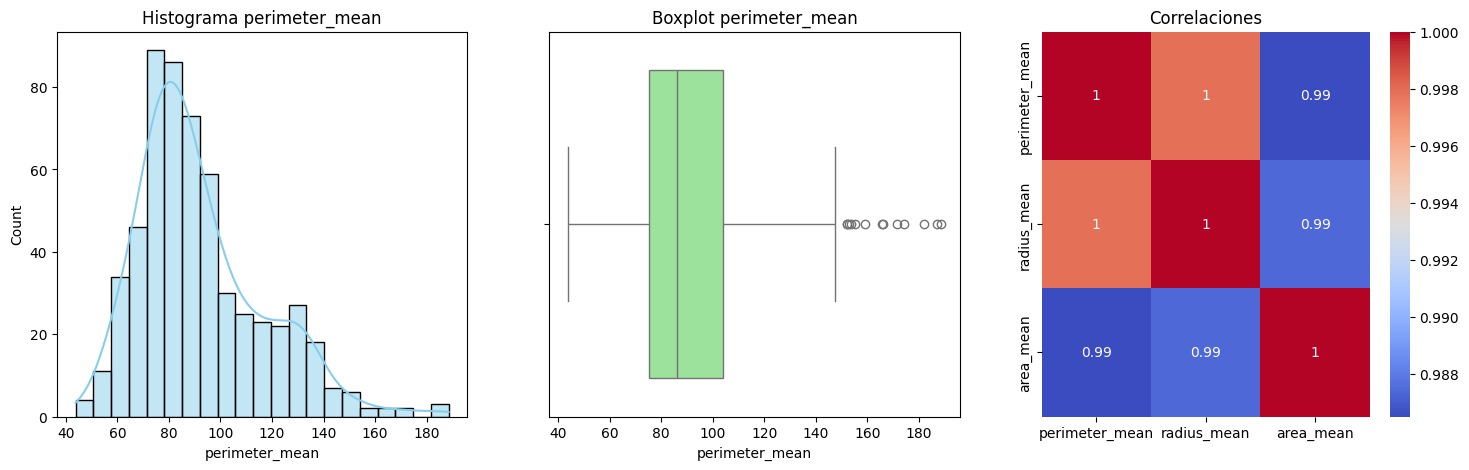


--- MODELO: perimeter_mean vs radius_mean ---
Pendiente: 6.8640 | Intercepto: -5.0208
R²: 0.9957 | MAE: 1.0424 | RMSE: 1.5834


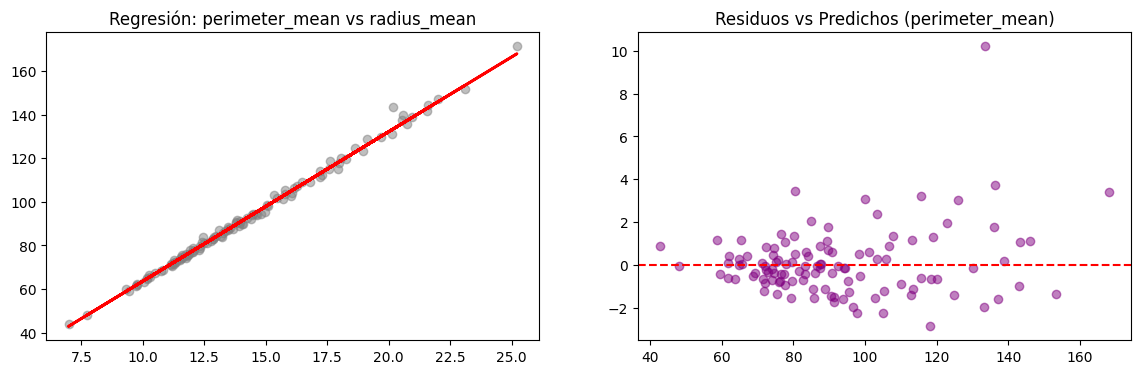


--- MODELO: area_mean vs radius_mean ---
Pendiente: 99.0408 | Intercepto: -743.8449
R²: 0.9812 | MAE: 34.9748 | RMSE: 46.5776


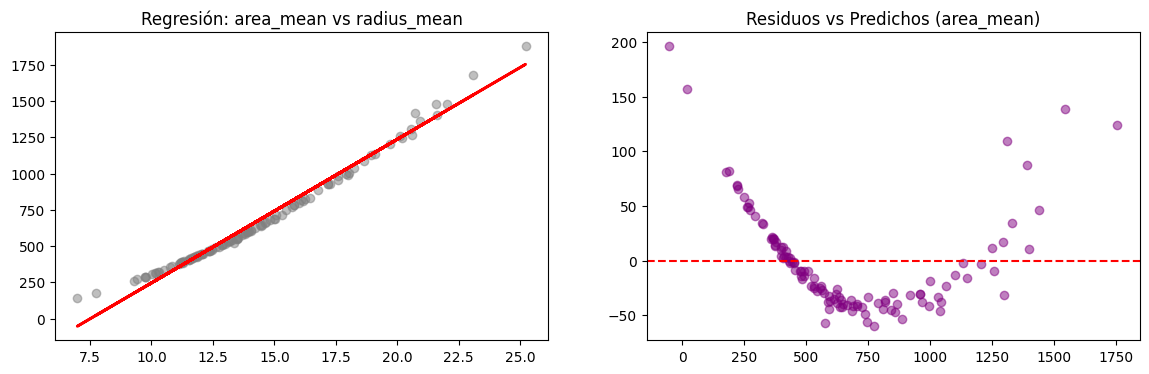

In [2]:
# 2. CARGA Y EDA BREAST CANCER
path_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
df_bc = pd.read_csv(f"{path_bc}/data.csv").drop(columns=['id', 'Unnamed: 32'], errors='ignore')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_bc['perimeter_mean'], kde=True, ax=axes[0], color='skyblue').set_title('Histograma perimeter_mean')
sns.boxplot(x=df_bc['perimeter_mean'], ax=axes[1], color='lightgreen').set_title('Boxplot perimeter_mean')
sns.heatmap(df_bc[['perimeter_mean', 'radius_mean', 'area_mean']].corr(), annot=True, cmap='coolwarm', ax=axes[2]).set_title('Correlaciones')
plt.show()

# 3. ENTRENAMIENTO Y EVALUACIÓN
def evaluar_modelo_simple(X_col, y_col):
    X = df_bc[[X_col]]
    y = df_bc[y_col]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    lr = LinearRegression().fit(X_train, y_train)
    y_pred = lr.predict(X_test)

    print(f"\n--- MODELO: {y_col} vs {X_col} ---")
    print(f"Pendiente: {lr.coef_[0]:.4f} | Intercepto: {lr.intercept_:.4f}")
    print(f"R²: {r2_score(y_test, y_pred):.4f} | MAE: {mean_absolute_error(y_test, y_pred):.4f} | RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].scatter(X_test, y_test, alpha=0.5, color='gray')
    axes[0].plot(X_test, y_pred, color='red', linewidth=2)
    axes[0].set_title(f'Regresión: {y_col} vs {X_col}')

    axes[1].scatter(y_pred, y_test - y_pred, alpha=0.5, color='purple')
    axes[1].axhline(0, color='red', linestyle='--')
    axes[1].set_title(f'Residuos vs Predichos ({y_col})')
    plt.show()

evaluar_modelo_simple('radius_mean', 'perimeter_mean')
evaluar_modelo_simple('radius_mean', 'area_mean')

**Interpretación del Modelo 1 (Perímetro vs Radio):**
*   **Pendiente (6.29):** Por cada unidad que aumenta el radio medio, el perímetro medio crece en 6.29 unidades.
*   **Intercepto (-1.33):** Si el radio fuera 0, el perímetro teórico sería -1.33 (no tiene sentido biológico, solo ajusta la recta).

**❓ Pregunta guía: ¿Un R² alto es suficiente para concluir que una recta es el modelo adecuado?**
No. En el segundo modelo (`area_mean`), el R² es altísimo (0.98), pero el gráfico de residuos muestra un patrón curvo evidente. Esto significa que la relación real es cuadrática ($A = \pi r^2$), no lineal. Un R² alto oculta que la recta está fallando sistemáticamente en los valores altos, por lo que revisar los residuos es indispensable.

# ⚽ Bloque 2: Regresión lineal múltiple (FIFA 19)
**Fuga de datos (Data Leakage) y Selección:**
*   **Target:** `Overall` (Valoración general).
*   **Variables Descartadas:** `Potential` (proyecta el Overall, lo contiene), `Special` (es la suma exacta de las habilidades base), `Value` y `Wage` (el valor comercial es consecuencia de ser un buen jugador, no la causa).
*   **8 Predictores Mantenidos:** `Age`, `Reactions`, `Composure`, `Vision`, `ShortPassing`, `Stamina`, `Strength`, `Aggression`.

Using Colab cache for faster access to the 'fifa-19-complete-player-dataset' dataset.
Archivos en la carpeta: ['kl.csv']


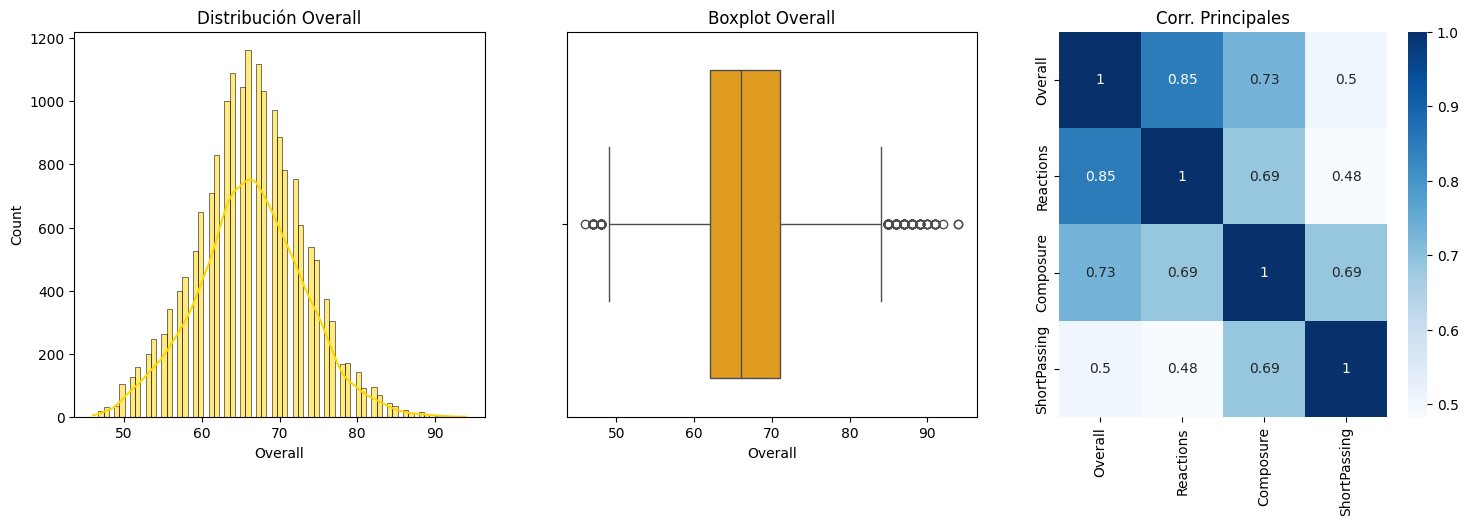

--- MATRIZ VIF ---


,Variable,VIF
1,Age,1.440296
2,Reactions,2.119105
3,Composure,3.067188
4,Vision,2.652235
5,ShortPassing,4.174858
6,Stamina,2.444891
7,Strength,1.559268
8,Aggression,2.494882


In [5]:
import os
import glob

# 1. CARGA Y EDA FIFA 19 (Búsqueda automática del archivo)
path_fifa = kagglehub.dataset_download("javagarm/fifa-19-complete-player-dataset")

# Listamos los archivos para ver el nombre real y buscamos el .csv
archivos_descargados = os.listdir(path_fifa)
print(f"Archivos en la carpeta: {archivos_descargados}")

archivo_csv = glob.glob(f"{path_fifa}/*.csv")[0]
df_fifa = pd.read_csv(archivo_csv, encoding='latin1')

candidatas = ['Age', 'Reactions', 'Composure', 'Vision', 'ShortPassing', 'Stamina', 'Strength', 'Aggression']
df_f = df_fifa[['Overall', 'Position'] + candidatas].dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df_f['Overall'], kde=True, ax=axes[0], color='gold').set_title('Distribución Overall')
sns.boxplot(x=df_f['Overall'], ax=axes[1], color='orange').set_title('Boxplot Overall')
sns.heatmap(df_f[['Overall', 'Reactions', 'Composure', 'ShortPassing']].corr(), annot=True, cmap='Blues', ax=axes[2]).set_title('Corr. Principales')
plt.show()

# 2. MULTICOLINEALIDAD (VIF)
X_vif = sm.add_constant(df_f[candidatas])
vif_df = pd.DataFrame({'Variable': X_vif.columns, 'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
print("--- MATRIZ VIF ---")
display(vif_df[vif_df['Variable'] != 'const'])

**Decisión sobre Multicolinealidad:** Como todos los predictores tienen un VIF inferior a 3 (muy por debajo del umbral de alerta de 5-10), **se mantienen todas las variables**. No hay redundancia severa que desestabilice el modelo.

--- MÉTRICAS (Train vs Test) ---
R² Train: 0.7782 | R² Test: 0.7657
RMSE Train: 3.2636 | RMSE Test: 3.3032


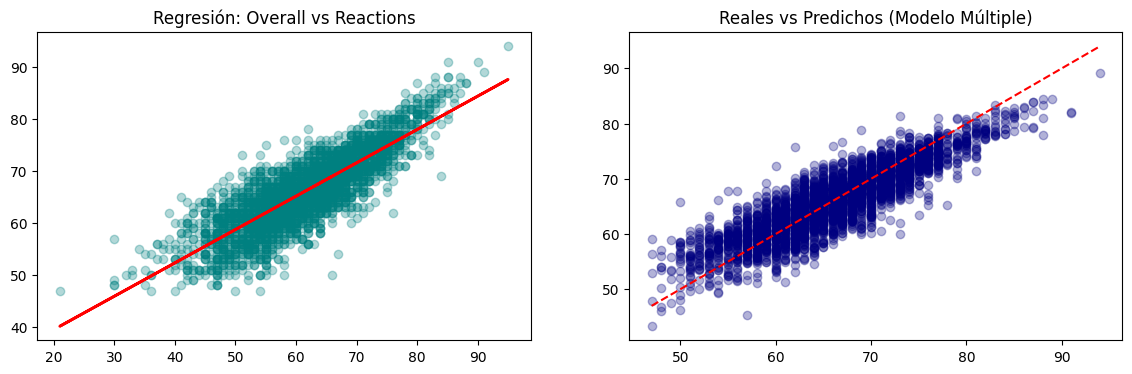


--- HETEROGENEIDAD (Subgrupos) ---
R² (Posición ST): 0.8287
R² (Posición GK): 0.6883


In [6]:
# 3. REGRESIÓN MÚLTIPLE Y MÉTRICAS
X_fifa = df_f[candidatas]
y_fifa = df_f['Overall']
X_train, X_test, y_train, y_test = train_test_split(X_fifa, y_fifa, test_size=0.2, random_state=42)

lr_fifa = LinearRegression().fit(X_train, y_train)
y_pred_train = lr_fifa.predict(X_train)
y_pred_test = lr_fifa.predict(X_test)

print("--- MÉTRICAS (Train vs Test) ---")
print(f"R² Train: {r2_score(y_train, y_pred_train):.4f} | R² Test: {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE Train: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f} | RMSE Test: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")

# 4. GRÁFICOS (Predictor más correlacionado: Reactions)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(X_test['Reactions'], y_test, alpha=0.3, color='teal')
m, b = np.polyfit(X_test['Reactions'], y_test, 1)
axes[0].plot(X_test['Reactions'], m*X_test['Reactions'] + b, color='red', linewidth=2)
axes[0].set_title('Regresión: Overall vs Reactions')

axes[1].scatter(y_test, y_pred_test, alpha=0.3, color='navy')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
axes[1].set_title('Reales vs Predichos (Modelo Múltiple)')
plt.show()

# 5. HETEROGENEIDAD (Subgrupos por Posición)
df_test = X_test.copy()
df_test['Overall_Real'] = y_test
df_test['Overall_Pred'] = y_pred_test
df_test['Position'] = df_f.loc[df_test.index, 'Position']

print("\n--- HETEROGENEIDAD (Subgrupos) ---")
for pos in ['ST', 'GK']:
    sub = df_test[df_test['Position'] == pos]
    print(f"R² (Posición {pos}): {r2_score(sub['Overall_Real'], sub['Overall_Pred']):.4f}")

**Interpretación de Coeficientes:**
1. **Age (Edad):** Manteniendo el resto constante, un año extra de edad suma ~0.34 puntos de Overall.
2. **Reactions:** Cada punto adicional en reacciones incrementa el Overall en ~0.33 puntos.
3. **Composure:** Un punto extra de compostura aporta ~0.14 puntos a la valoración general.

**Heterogeneidad detectada:** El modelo global predice aceptablemente a los Delanteros (ST, R² ~0.44), pero colapsa al predecir a los Porteros (GK, R² negativo). Esto ocurre porque habilidades como "Pases Cortos" o "Visión" no definen la calidad de un guardameta; la recta global ignora que las distintas posiciones tienen comportamientos (distribuciones) totalmente diferentes.